# Évaluation finale sur le jeu de test

C'est le moment que tout le projet prépare. Le modèle a été choisi à l'étape précédente, **par validation croisée sur l'entraînement uniquement** : le gradient boosting avec poids équilibrés. Le jeu de test `KDDTest+` n'a servi à aucun choix. On le mesure ici, et **on ne retouchera pas le modèle à la lumière de ces résultats** : sinon, le test deviendrait un second jeu de validation et ses chiffres ne voudraient plus rien dire.

Trois modèles sont mesurés, pour situer le résultat : la référence naïve, la régression logistique, et le modèle retenu.

Le modèle retenu prédit une des cinq familles. Pour la détection « normal ou attaque », une connexion est signalée dès que la famille prédite n'est pas « normal », et le score d'attaque est 1 moins la probabilité de « normal ». Un seul modèle sert donc aux deux lectures.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance

from intrusion_detector.data import (
    CATEGORIES,
    PROJECT_ROOT,
    load_test,
    load_train,
    split_features_target,
)
from intrusion_detector.evaluate import (
    attack_score,
    binary_metrics_from_families,
    per_class_report,
    plot_confusion_matrix,
)
from intrusion_detector.models import baseline_models
from intrusion_detector.train import FINAL_MODEL_NAME, MODEL_PATH, save_model, train_final_model

sns.set_theme(style="whitegrid", context="notebook")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

train = load_train()
test = load_test()
X_train, y_train = split_features_target(train, target="category")
X_test, y_test = split_features_target(test, target="category")
y_train, y_test = y_train.astype(str), y_test.astype(str)

In [2]:
reference = baseline_models()
models = {
    "Référence (classe majoritaire)": reference["Référence (classe majoritaire)"].fit(X_train, y_train),
    "Régression logistique": reference["Régression logistique"].fit(X_train, y_train),
    FINAL_MODEL_NAME: train_final_model(train),
}

save_model(models[FINAL_MODEL_NAME])
print(f"Modèle final enregistré dans {MODEL_PATH.relative_to(PROJECT_ROOT)}")

Modèle final enregistré dans models\final_model.joblib


## 1. Résultats sur KDDTest+

In [3]:
predictions = {name: model.predict(X_test) for name, model in models.items()}

NAMES = {
    "accuracy": "accuracy",
    "precision": "précision",
    "recall": "rappel",
    "f1": "F1",
    "roc_auc": "ROC AUC",
}

rows = {}
for name, model in models.items():
    binary = binary_metrics_from_families(y_test, predictions[name], attack_score(model, X_test))
    report = per_class_report(y_test, predictions[name])
    rows[name] = {
        **{f"binaire, {NAMES[key]}": value for key, value in binary.items()},
        "5 familles, F1 macro": report.loc["macro avg", "f1"],
    }

results = pd.DataFrame(rows).T
results.round(3)

,"binaire, accuracy","binaire, précision","binaire, rappel","binaire, F1","binaire, ROC AUC","5 familles, F1 macro"
Référence (classe majoritaire),0.431,0.000,0.000,0.000,0.500,0.120
Régression logistique,0.767,0.924,0.643,0.759,0.916,0.528
Gradient boosting (poids équilibrés),0.820,0.969,0.706,0.817,0.940,0.622


**Le modèle retenu reste le meilleur des trois, mais ses scores sont très loin de ceux de la validation croisée.** En détection binaire, il atteint 81,5 % d'accuracy, une précision de 96,9 % et un rappel de 69,7 % (F1 de 0,811, ROC AUC de 0,932). Sur cinq familles, son F1 macro est de 0,614. La régression logistique fait moins bien partout (F1 binaire de 0,760, F1 macro de 0,528) : le classement établi en validation croisée se retrouve sur le test.

Le profil est particulier : **peu de fausses alertes, mais près d'une attaque sur trois manquée**. La précision est élevée parce que le modèle ne signale que ce dont il est sûr ; le rappel est bas parce que de nombreuses attaques du test ne ressemblent à rien de ce qu'il a appris.

Un détail sur la référence naïve : son accuracy est de 43,1 % ici, contre 53,5 % à l'entraînement, simplement parce que le trafic normal pèse moins dans le test. L'accuracy d'une référence dépend des proportions du jeu de données, une raison de plus de ne pas s'y fier.

Ces niveaux sont du même ordre de grandeur que ce que rapportent de nombreux travaux sur ce jeu de test (souvent autour de 75 à 85 % d'accuracy en détection binaire pour des modèles classiques). C'est le score de validation croisée qui n'était pas représentatif.

### Validation croisée contre test

Les F1 macro de la validation croisée viennent des notebooks 02 et 03.

In [4]:
CV_F1_MACRO = {
    "Référence (classe majoritaire)": 0.139,
    "Régression logistique": 0.845,
    FINAL_MODEL_NAME: 0.919,
}

comparison = pd.DataFrame(
    {"validation croisée": pd.Series(CV_F1_MACRO), "test": results["5 familles, F1 macro"]}
)
comparison["écart"] = comparison["test"] - comparison["validation croisée"]
comparison.round(3)

,validation croisée,test,écart
Référence (classe majoritaire),0.139,0.120,-0.019
Régression logistique,0.845,0.528,-0.317
Gradient boosting (poids équilibrés),0.919,0.622,-0.297


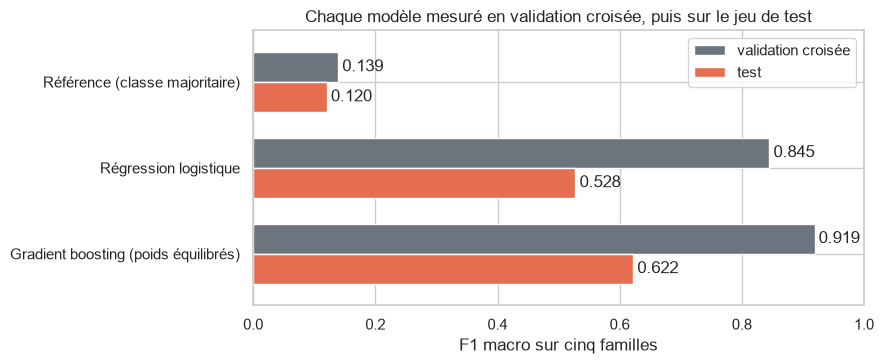

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
comparison[["validation croisée", "test"]].plot.barh(ax=ax, color=["#6c757d", "#e76f51"], width=0.7)
ax.set_xlim(0, 1)
ax.set_xlabel("F1 macro sur cinq familles")
ax.set_ylabel("")
ax.set_title("Chaque modèle mesuré en validation croisée, puis sur le jeu de test")
ax.invert_yaxis()
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "cv_vs_test.png", dpi=150)
plt.show()

Le F1 macro du modèle retenu passe de 0,919 à 0,614, et celui de la régression logistique de 0,845 à 0,528 : une chute de plus de 30 points dans les deux cas. Les modèles ne sont pas devenus mauvais, c'est la mesure qui a changé. En validation croisée, chaque connexion à prédire ressemble à des connexions d'apprentissage ; dans le test, ce n'est plus vrai. Seule la référence naïve bouge peu (0,139 à 0,120), puisqu'elle n'apprend rien.

Cet écart est le résultat central du projet : sur ce jeu de données, un score de validation croisée mesure la capacité à reconnaître ce qu'on a déjà vu, pas à détecter des attaques nouvelles.

### Famille par famille, pour le modèle retenu

In [6]:
final = models[FINAL_MODEL_NAME]
final_predictions = predictions[FINAL_MODEL_NAME]

per_class_report(y_test, final_predictions).round(3)

,precision,recall,f1,support
normal,0.714,0.971,0.823,9711
dos,0.963,0.788,0.867,7458
probe,0.813,0.792,0.802,2421
r2l,0.960,0.296,0.452,2754
u2r,0.655,0.095,0.166,200
macro avg,0.821,0.588,0.622,22544


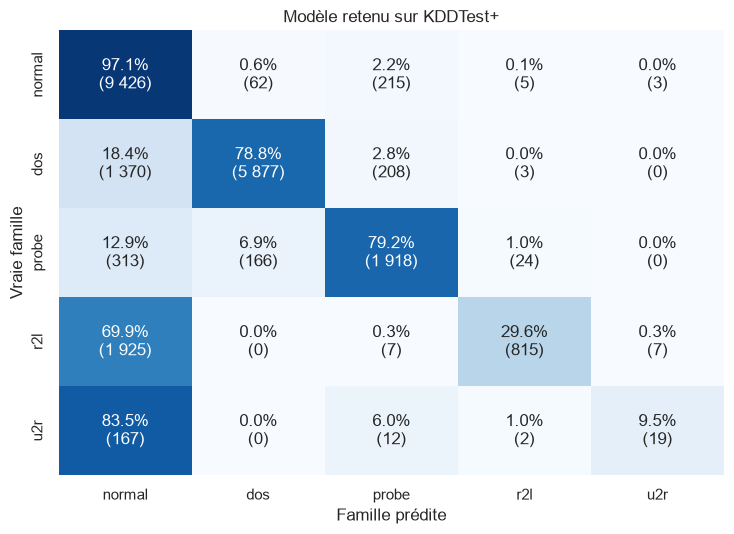

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
plot_confusion_matrix(
    y_test,
    final_predictions,
    title="Modèle retenu sur KDDTest+",
    ax=ax,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "final_confusion_matrix.png", dpi=150)
plt.show()

Les erreurs vont presque toutes dans la même direction : **vers « normal »**.

- **R2L** : 27,2 % détectées seulement. 1 988 connexions sur 2 754 (72,2 %) sont prises pour du trafic normal. La précision, elle, est de 0,968 : quand le modèle annonce du R2L, il a presque toujours raison.
- **U2R** : 9,0 % détectées (18 sur 200). 171 connexions sur 200 passent pour du trafic normal.
- **DoS** : 78,7 % détectées, mais 1 410 connexions DoS (18,9 %) sont prises pour du trafic normal.
- **Probe** : 79,3 % détectées, dont 319 connexions prises pour du trafic normal.
- **Trafic normal** : 97,0 % correctement reconnu. 288 connexions normales sur 9 711 (3,0 %) sont signalées à tort comme des attaques.

La précision de la famille « normal » n'est que de 0,708 : c'est le miroir des attaques manquées, qui se retrouvent toutes dans cette colonne.

## 2. D'où vient l'écart ? Les attaques jamais vues

Dans `KDDTest+`, 17 types d'attaques n'existent pas dans l'entraînement. Ici, on sépare les attaques du test selon que leur type a été vu ou non à l'entraînement, et on regarde la part détectée (signalée comme n'importe quelle attaque).

In [8]:
known_labels = set(train["label"])
is_attack = test["is_attack"] == 1
flagged = pd.Series(final_predictions != "normal", index=test.index)

attacks = test[is_attack].assign(
    detectee=flagged[is_attack],
    type_connu=test.loc[is_attack, "label"].isin(known_labels),
)

by_known = attacks.groupby("type_connu")["detectee"].agg(["mean", "count"])
by_known.index = by_known.index.map({True: "type vu à l'entraînement", False: "type jamais vu"})
by_known.columns = ["part détectée", "connexions"]
by_known.round(3)

,part détectée,connexions
type_connu,,
type jamais vu,0.370,3750
type vu à l'entraînement,0.845,9083


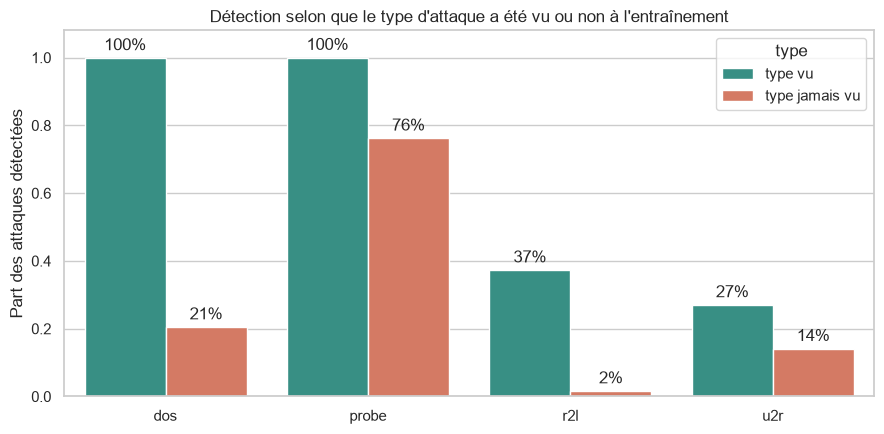

,category,type_connu,part détectée,connexions
0,dos,False,0.205,1717
1,dos,True,0.999,5741
2,probe,False,0.762,1315
3,probe,True,1.000,1106
4,r2l,False,0.016,555
5,r2l,True,0.373,2199
6,u2r,False,0.141,163
7,u2r,True,0.270,37


In [9]:
by_family = (
    attacks.groupby(["category", "type_connu"], observed=True)["detectee"]
    .agg(["mean", "count"])
    .reset_index()
)
by_family["type"] = by_family["type_connu"].map({True: "type vu", False: "type jamais vu"})

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    data=by_family,
    x="category",
    y="mean",
    hue="type",
    order=[c for c in CATEGORIES if c != "normal"],
    hue_order=["type vu", "type jamais vu"],
    palette=["#2a9d8f", "#e76f51"],
    ax=ax,
)
ax.set_ylim(0, 1.08)
ax.set_xlabel("")
ax.set_ylabel("Part des attaques détectées")
ax.set_title("Détection selon que le type d'attaque a été vu ou non à l'entraînement")
for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f"{v:.0%}", padding=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "seen_vs_unseen.png", dpi=150)
plt.show()

by_family.drop(columns="type").rename(columns={"mean": "part détectée", "count": "connexions"}).round(3)

In [10]:
by_label = (
    attacks.groupby("label")
    .agg(famille=("category", "first"), connexions=("label", "size"), part_detectee=("detectee", "mean"))
    .assign(type_connu=lambda d: d.index.isin(known_labels))
    .sort_values("connexions", ascending=False)
    .head(12)
)
by_label["part_detectee"] = (by_label["part_detectee"] * 100).round(1)
by_label.rename(columns={"part_detectee": "détectée (%)", "type_connu": "type vu"})

,famille,connexions,détectée (%),type vu
label,,,,
neptune,dos,4657,100.0,True
guess_passwd,r2l,1231,3.4,True
mscan,probe,996,68.9,False
warezmaster,r2l,944,81.4,True
apache2,dos,737,25.0,False
satan,probe,735,100.0,True
processtable,dos,685,21.9,False
smurf,dos,665,100.0,True
back,dos,359,100.0,True


**Les attaques d'un type vu à l'entraînement sont détectées à 83,7 %, celles d'un type jamais vu à 35,8 %.** C'est l'explication principale de l'écart avec la validation croisée. Les 3 750 connexions d'un type inconnu représentent près de 30 % des attaques du test.

Le détail par famille :

- **DoS** : 99,8 % de détection sur les types connus, 18,4 % sur les types nouveaux. Les DoS connus (`neptune`, `smurf`, `back`) sont reconnus presque parfaitement ; les nouveaux (`apache2` 25 %, `processtable` 19 %, `mailbomb` 0 %) ressemblent assez peu aux précédents pour passer inaperçus.
- **Probe** : 100 % sur les types connus, 75,7 % sur les nouveaux. C'est la famille qui généralise le mieux : les nouveaux types (`mscan` 68 %, `saint` 99 %) restent des balayages, au comportement réseau proche de ceux appris.
- **R2L** et **U2R** : très faible dans les deux cas, et pas seulement sur les types nouveaux. Les 37 connexions U2R d'un type connu ne sont détectées qu'à 29,7 %.

**Un second phénomène que « type jamais vu » n'explique pas.** `guess_passwd` est un type connu, mais il n'a que 53 exemples à l'entraînement alors que le test en contient 1 231 : il n'est détecté qu'à 3,4 %. `warezmaster` passe de 20 exemples d'entraînement à 944 dans le test. À eux deux, ces types font 79 % des connexions R2L du test, pour seulement 73 exemples d'entraînement. Ce n'est donc pas qu'un manque de types : c'est aussi un déséquilibre massif entre ce qu'on apprend et ce qu'on doit détecter.

## 3. Le sous-ensemble difficile : KDDTest-21

`KDDTest-21` est une version plus difficile du test, publiée avec le jeu de données : elle retire les connexions que tous les classifieurs de référence réussissent. On la reconstitue avec la colonne `difficulty`, utilisée ici uniquement pour filtrer l'évaluation, jamais comme variable du modèle.

In [11]:
hard = (test["difficulty"] < 21).to_numpy()
print(f"KDDTest-21 : {hard.sum():,} connexions sur {len(test):,}".replace(",", " "))

hard_binary = binary_metrics_from_families(
    y_test[hard], final_predictions[hard], attack_score(final, X_test[hard])
)
hard_report = per_class_report(y_test[hard], final_predictions[hard])

comparison_hard = pd.DataFrame(
    {
        "KDDTest+": {
            "accuracy (binaire)": results.loc[FINAL_MODEL_NAME, "binaire, accuracy"],
            "rappel (binaire)": results.loc[FINAL_MODEL_NAME, "binaire, rappel"],
            "précision (binaire)": results.loc[FINAL_MODEL_NAME, "binaire, précision"],
            "F1 macro (5 familles)": results.loc[FINAL_MODEL_NAME, "5 familles, F1 macro"],
        },
        "KDDTest-21": {
            "accuracy (binaire)": hard_binary["accuracy"],
            "rappel (binaire)": hard_binary["recall"],
            "précision (binaire)": hard_binary["precision"],
            "F1 macro (5 familles)": hard_report.loc["macro avg", "f1"],
        },
    }
)
comparison_hard.round(3)

KDDTest-21 : 11 850 connexions sur 22 544


,KDDTest+,KDDTest-21
accuracy (binaire),0.820,0.658
rappel (binaire),0.706,0.611
précision (binaire),0.969,0.954
F1 macro (5 familles),0.622,0.530


Sur `KDDTest-21` (11 850 connexions, la taille de la version publiée, ce qui confirme que la reconstitution est correcte), les scores baissent encore : accuracy binaire de 64,8 %, rappel de 59,9 %, F1 macro de 0,522. La précision reste élevée (95,3 %). Ce sous-ensemble ne garde que les connexions que des classifieurs de référence ont eu du mal à classer : c'est une borne basse, pas une mesure représentative d'un usage courant.

## 4. Quelles variables comptent ?

On mélange au hasard une variable à la fois dans le jeu de test et on mesure de combien le F1 macro baisse : plus la baisse est grande, plus le modèle s'appuie sur cette variable. C'est un diagnostic d'explication, il ne sert pas à modifier le modèle.

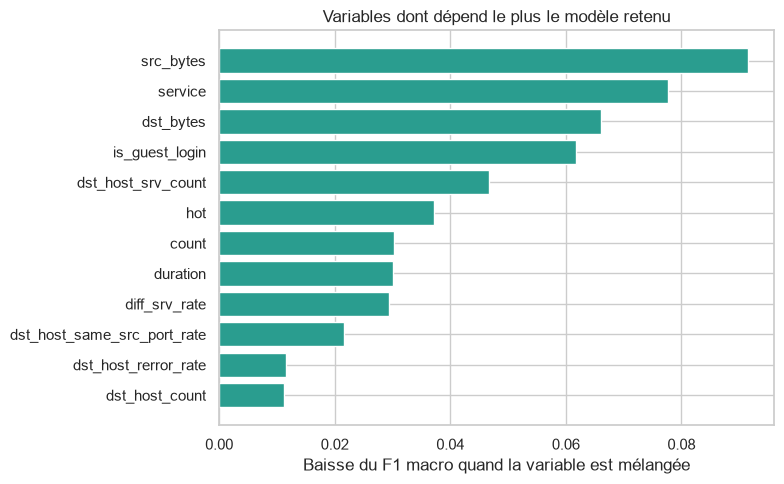

,baisse du F1 macro
src_bytes,0.091
service,0.078
dst_bytes,0.066
is_guest_login,0.062
dst_host_srv_count,0.047
hot,0.037
count,0.030
duration,0.030
diff_srv_rate,0.029
dst_host_same_src_port_rate,0.022


In [12]:
importance = permutation_importance(
    final, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=42, n_jobs=2
)
importances = pd.Series(importance.importances_mean, index=X_test.columns).sort_values(ascending=False)

top = importances.head(12).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color="#2a9d8f")
ax.set_xlabel("Baisse du F1 macro quand la variable est mélangée")
ax.set_title("Variables dont dépend le plus le modèle retenu")
fig.tight_layout()
fig.savefig(FIG_DIR / "permutation_importance.png", dpi=150)
plt.show()

importances.head(12).round(3).to_frame("baisse du F1 macro")

Le modèle s'appuie surtout sur les volumes d'octets échangés (`dst_bytes`, `src_bytes`) et sur le type de service (`service`), puis sur `is_guest_login`, `dst_host_srv_count` et `hot`. Les taux d'erreurs de connexion, qui dominaient les corrélations de l'exploration, n'apparaissent pas parmi les douze premières variables : ces corrélations décrivaient surtout le DoS, alors que l'importance mesurée ici porte sur le F1 macro des cinq familles.

Deux réserves. Cette importance est calculée sur le jeu de test, dont la distribution diffère de l'entraînement : elle décrit ce dont dépend le modèle sur ces données, pas une vérité générale sur les attaques. Et des variables corrélées entre elles se partagent l'importance, ce qui sous-estime chacune d'elles.

## 5. Conclusion

- **Le résultat, sans l'enjoliver** : sur le jeu de test, le modèle retenu atteint 81,5 % d'accuracy en détection binaire (précision 96,9 %, rappel 69,7 %) et un F1 macro de 0,614 sur cinq familles. Il bat nettement la régression logistique et la référence naïve, mais reste très loin des 0,919 de la validation croisée.
- **Ce qu'il fait bien** : il se trompe rarement quand il signale une attaque (peu de fausses alertes), et il reconnaît presque parfaitement les types de DoS et de Probe qu'il a appris.
- **Ce qu'il ne fait pas** : il ne généralise pas aux attaques nouvelles (35,8 % de détection contre 83,7 % pour les types connus), et il rate la quasi-totalité des attaques R2L et U2R, qui ressemblent à des sessions légitimes. Il ne peut donc pas être présenté comme un système de défense.
- **Les limites du jeu de données comptent autant que celles du modèle** : NSL-KDD dérive de trafic de 1999, et son jeu de test est volontairement décalé de l'entraînement, en types d'attaques comme en proportions.
- **Pistes d'amélioration** : une validation croisée groupée par type d'attaque, qui donnerait dès l'entraînement une estimation réaliste ; des méthodes de détection d'anomalies, qui apprennent le trafic normal et signalent ce qui s'en écarte sans dépendre des attaques déjà connues ; des jeux de données plus récents.